<a href="https://colab.research.google.com/github/Bhavesh1412/CSL701-CS33_Machine-Learning-Lab/blob/main/Experiment_8_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name :

Batch :


Roll Number :



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Load the Breast Cancer Wisconsin dataset from scikit-learn
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

df = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

print(df.head())


Saving brca.csv to brca (2).csv
   Unnamed: 0  x.radius_mean  x.texture_mean  x.perimeter_mean  x.area_mean  \
0           1         13.540           14.36             87.46        566.3   
1           2         13.080           15.71             85.63        520.0   
2           3          9.504           12.44             60.34        273.9   
3           4         13.030           18.42             82.61        523.8   
4           5          8.196           16.84             51.71        201.9   

   x.smoothness_mean  x.compactness_mean  x.concavity_mean  \
0            0.09779             0.08129           0.06664   
1            0.10750             0.12700           0.04568   
2            0.10240             0.06492           0.02956   
3            0.08983             0.03766           0.02562   
4            0.08600             0.05943           0.01588   

   x.concave_pts_mean  x.symmetry_mean  ...  x.texture_worst  \
0            0.047810           0.1885  ...            1

# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

In [5]:
# Check missing values and summary statistics
print("Missing values per column:")
print(df.isnull().sum())

print("\nFeature dimensions:")
print("Number of samples:", X.shape[0])
print("Number of numerical features:", X.shape[1])

print("\nSummary statistics:")
display(X.describe())

print("\nDiagnosis class distribution:")
print(diagnosis.value_counts())


Missing values per column:
Unnamed: 0             0
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64

Feature dimensions:
Number of samples: 569
Number of numerical features: 30

Summary statistics:


,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,x.fractal_dim_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500



Diagnosis class distribution:
y
B    357
M    212
Name: count, dtype: int64


# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [6]:
# Keep the numerical features and standardize them
X_numeric = X.select_dtypes(include=[np.number]).copy()
X_numeric = X_numeric.drop(columns=["id"], errors="ignore")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

print("Scaled feature matrix shape:", X_scaled.shape)
print("Mean of first 5 scaled features (approximately 0):")
print(np.round(X_scaled.mean(axis=0)[:5], 4))
print("Standard deviation of first 5 scaled features (approximately 1):")
print(np.round(X_scaled.std(axis=0)[:5], 4))


Scaled feature matrix shape: (569, 30)
Mean of first 5 scaled features (approximately 0):
[-0. -0. -0. -0.  0.]
Standard deviation of first 5 scaled features (approximately 1):
[1. 1. 1. 1. 1.]


# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [7]:
# Compute all pairwise Euclidean distances between samples
distance_matrix = squareform(pdist(X_scaled, metric="euclidean"))

print("Distance matrix shape:", distance_matrix.shape)
print("Distance between sample 0 and sample 1:", round(distance_matrix[0, 1], 4))

# The matrix represents a weighted complete graph:
# each sample is a node and each pair has an edge weighted by distance.
print("Number of samples (nodes):", distance_matrix.shape[0])
print("Number of possible undirected edges:", distance_matrix.shape[0] * (distance_matrix.shape[0] - 1) // 2)


Distance matrix shape: (569, 569)
Distance between sample 0 and sample 1: 3.1072
Number of samples (nodes): 569
Number of possible undirected edges: 161596


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [8]:
# Calculate the Minimum Spanning Tree using SciPy
mst_sparse = minimum_spanning_tree(csr_matrix(distance_matrix))
mst_matrix = mst_sparse.toarray()

# Extract MST edges as (source node, destination node, weight)
mst_edges = [
    (i, j, mst_matrix[i, j])
    for i in range(mst_matrix.shape[0])
    for j in range(mst_matrix.shape[1])
    if mst_matrix[i, j] > 0
]

print("Number of MST edges:", len(mst_edges))
print("Expected number of edges for a connected MST:", len(X_scaled) - 1)
print("\nFirst 10 MST edges (node1, node2, distance):")
print(mst_edges[:10])

# Build a NetworkX graph for convenient plotting and component analysis
G_mst = nx.Graph()
G_mst.add_nodes_from(range(len(X_scaled)))
G_mst.add_weighted_edges_from(mst_edges)


Number of MST edges: 568
Expected number of edges for a connected MST: 568

First 10 MST edges (node1, node2, distance):
[(0, 81, np.float64(1.688589884751502)), (0, 108, np.float64(2.1714476618283567)), (1, 105, np.float64(1.6607267131218872)), (2, 70, np.float64(2.218949334515698)), (3, 170, np.float64(2.346213328330311)), (3, 222, np.float64(2.5415242027912224)), (4, 84, np.float64(2.166020221845041)), (4, 279, np.float64(1.8603236849319482)), (5, 125, np.float64(1.7658726578704034)), (5, 172, np.float64(2.0170999016357793))]


# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [9]:
# Remove the largest edge from the MST to create K=2 clusters
K = 2
edges_descending = sorted(mst_edges, key=lambda edge: edge[2], reverse=True)
largest_edges = edges_descending[:K - 1]

print("Largest edge selected for removal:", largest_edges[0])

G_cluster = G_mst.copy()
for u, v, weight in largest_edges:
    G_cluster.remove_edge(u, v)

components = list(nx.connected_components(G_cluster))
cluster_labels = np.zeros(len(X_scaled), dtype=int)

for cluster_id, component in enumerate(components):
    for node in component:
        cluster_labels[node] = cluster_id

print("Number of connected components / clusters:", len(components))
print("Cluster sizes:", pd.Series(cluster_labels).value_counts().sort_index().to_dict())


Largest edge selected for removal: (544, 553, np.float64(12.299945385815649))
Number of connected components / clusters: 2
Cluster sizes: {0: 567, 1: 2}


# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [11]:
# Evaluate the clustering against the known diagnosis labels
sil_score = silhouette_score(X_scaled, cluster_labels)
ari = adjusted_rand_score(y, cluster_labels)
nmi = normalized_mutual_info_score(y, cluster_labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

print("\nNote: cluster IDs (0 and 1) do not inherently correspond to malignant/benign.")
print("ARI and NMI compare partitions and do not require cluster IDs to match class IDs.")


Silhouette Score: 0.6607
Adjusted Rand Index (ARI): 0.0048
Normalized Mutual Information (NMI): 0.0102

Note: cluster IDs (0 and 1) do not inherently correspond to malignant/benign.
ARI and NMI compare partitions and do not require cluster IDs to match class IDs.


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

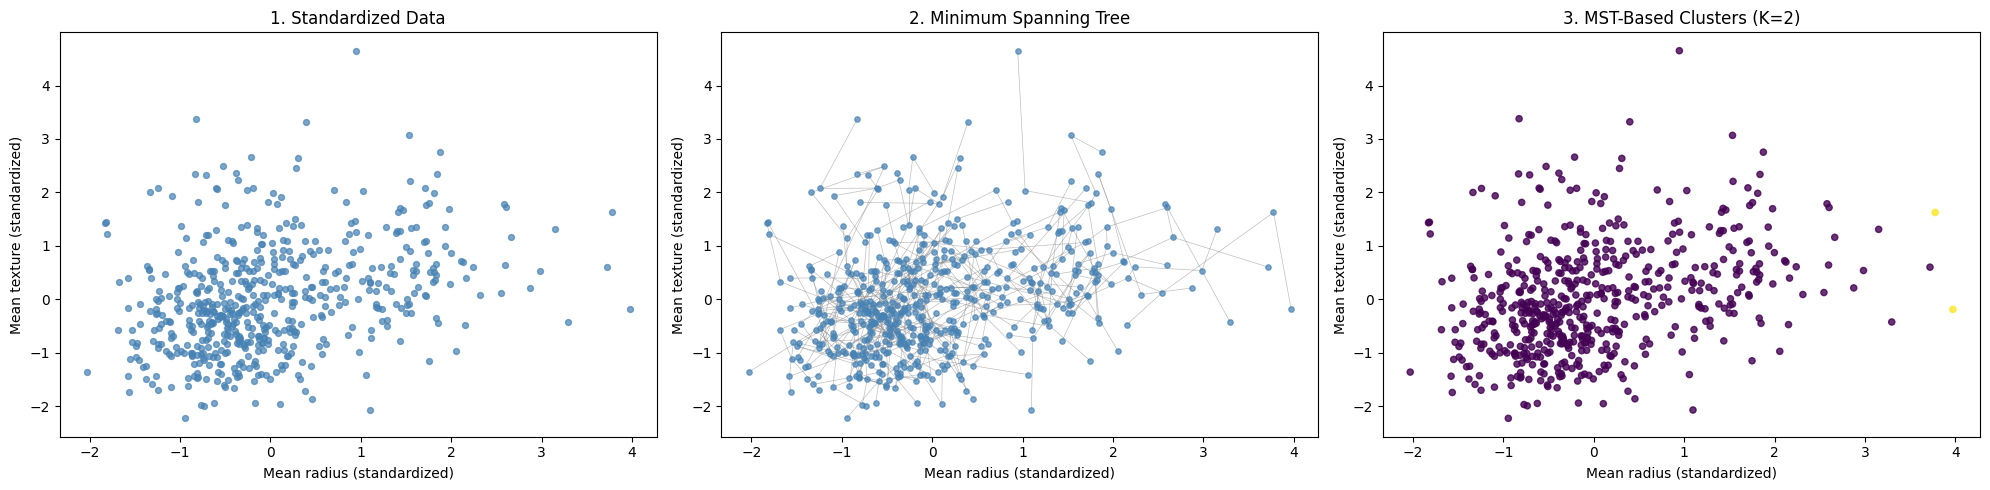

In [13]:
# Use mean radius and mean texture for the 2D visualizations
radius_col = "mean radius"
texture_col = "mean texture"
radius_idx = list(X_numeric.columns).index(radius_col)
texture_idx = list(X_numeric.columns).index(texture_col)

plot_x = X_scaled[:, radius_idx]
plot_y = X_scaled[:, texture_idx]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot 1: data before clustering
axes[0].scatter(plot_x, plot_y, c="steelblue", s=18, alpha=0.7)
axes[0].set_title("1. Standardized Data")
axes[0].set_xlabel("Mean radius (standardized)")
axes[0].set_ylabel("Mean texture (standardized)")

# Plot 2: MST edges overlaid on the data
axes[1].scatter(plot_x, plot_y, c="steelblue", s=15, alpha=0.7, zorder=2)
for u, v, weight in mst_edges:
    axes[1].plot([plot_x[u], plot_x[v]], [plot_y[u], plot_y[v]],
                 color="gray", linewidth=0.5, alpha=0.5, zorder=1)
axes[1].set_title("2. Minimum Spanning Tree")
axes[1].set_xlabel("Mean radius (standardized)")
axes[1].set_ylabel("Mean texture (standardized)")

# Plot 3: clusters after removing the largest MST edge
scatter = axes[2].scatter(plot_x, plot_y, c=cluster_labels, cmap="viridis",
                          s=20, alpha=0.8)
axes[2].set_title("3. MST-Based Clusters (K=2)")
axes[2].set_xlabel("Mean radius (standardized)")
axes[2].set_ylabel("Mean texture (standardized)")

plt.tight_layout()
plt.show()


# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.